# BÀI THỰC HÀNH SỐ 2 - BÀI 4 (Trang 26)
## Phân lớp chất lượng rượu vang đỏ — Red Wine Quality (`winequality-red.csv`)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Khảo sát tương quan Pearson, tiền xử lý đặc trưng và xây dựng, đánh giá, so sánh 3 mô hình phân lớp (**ID3**, **CART**, **Gaussian Naïve Bayes**) trên tập dữ liệu chất lượng rượu vang đỏ (`quality`).

## Thiết lập môi trường & Nạp dữ liệu `winequality-red.csv`

In [1]:
import os
import sys
import subprocess

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
print(f"{STUDENT_NAME} - {MSSV}")

DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1KK--zL3h4hWrfIl--FIcrww3dLx-epiB?usp=sharing"


def get_dataset_path(filename: str) -> str:
    """Tìm đường dẫn tập dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
        check=True,
    )
    if not os.path.exists(local_path):
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")
    return local_path

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

sns.set_style("whitegrid")

data_path = get_dataset_path("winequality-red.csv")
print(f"Đường dẫn dữ liệu: {data_path}")

# Lưu ý: Tệp winequality-red.csv trong Dataset dùng dấu phân tách ',' (comma-separated)
data = pd.read_csv(data_path)
print(f"Kích thước dữ liệu: {data.shape[0]} dòng, {data.shape[1]} cột")
print("\n--- Kiểm tra giá trị thiếu (NaN) ---")
print(data.isnull().sum())

print("\n--- Thông tin cấu trúc dữ liệu (info()) ---")
data.info()

print("\n--- 5 dòng đầu tiên (head()) ---")
display(data.head())

print("\n--- Phân bố nhãn quyết định 'quality' ---")
print(data["quality"].value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033


Đường dẫn dữ liệu: Dataset\winequality-red.csv
Kích thước dữ liệu: 1599 dòng, 12 cột

--- Kiểm tra giá trị thiếu (NaN) ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

--- Thông tin cấu trúc dữ liệu (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6 

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



--- Phân bố nhãn quyết định 'quality' ---
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Nguyễn Phạm Bảo Khanh - 6451071033
--- Top 8 cặp thuộc tính có độ tương đồng |r| cao nhất ---


Pearson_r
fixed acidity       pH                    -0.682978
                    citric acid            0.671703
                    density                0.668047
free sulfur dioxide total sulfur dioxide   0.667666
volatile acidity    citric acid           -0.552496
citric acid         pH                    -0.541904
density             alcohol               -0.496180
alcohol             quality                0.476166

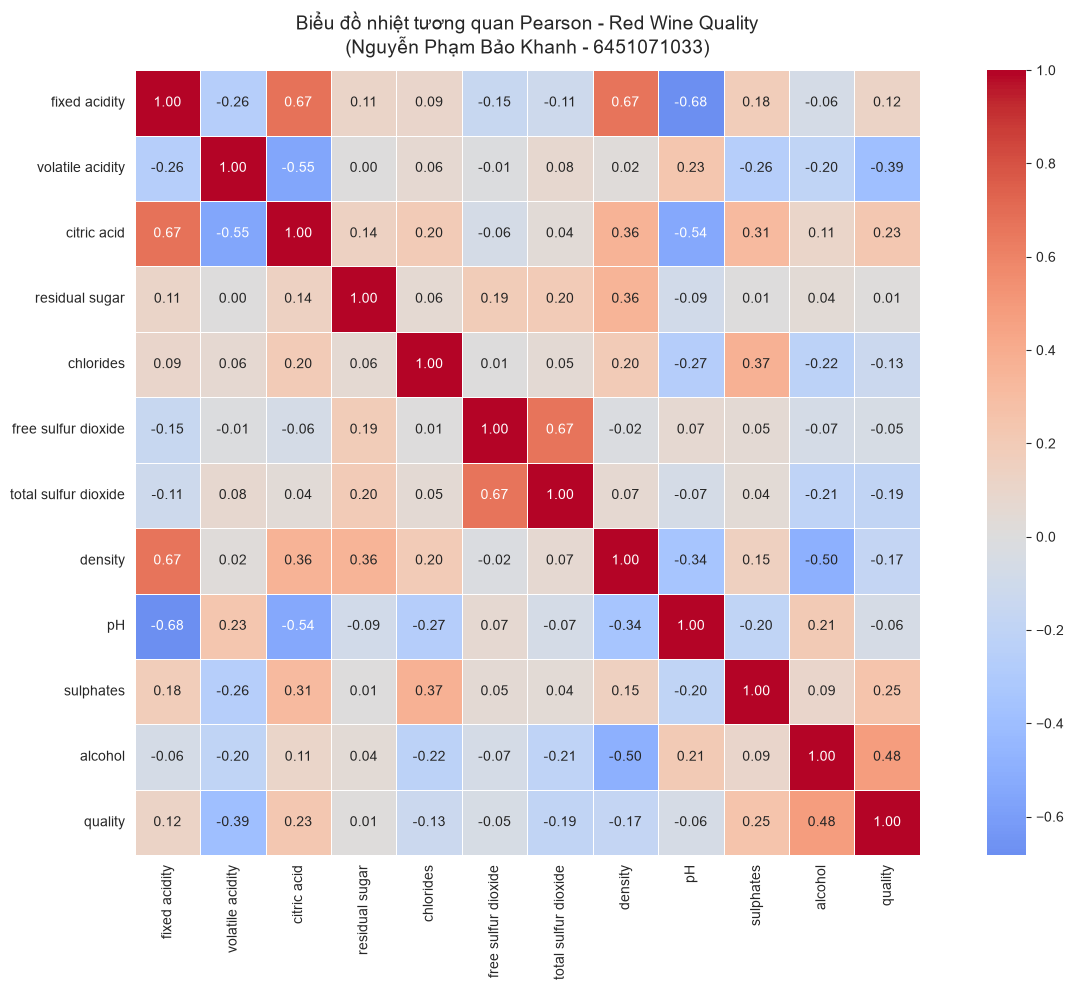

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

corr_matrix = data.corr(method="pearson")

# Thống kê các cặp thuộc tính có trị tuyệt đối hệ số tương quan lớn nhất
upper_mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
top_corr = corr_matrix.where(upper_mask).stack().sort_values(key=abs, ascending=False)
print("--- Top 8 cặp thuộc tính có độ tương đồng |r| cao nhất ---")
display(top_corr.head(8).to_frame(name="Pearson_r"))

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
)
plt.title(f"Biểu đồ nhiệt tương quan Pearson - Red Wine Quality\n({STUDENT_NAME} - {MSSV})", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

**Nhận xét Câu 3:**
- Cặp thuộc tính có độ tương đồng lớn nhất là `fixed acidity` và `pH` với hệ số tương quan `r ≈ -0.683` (tính axit cố định tăng thì pH giảm). Các cặp tiếp theo gồm `fixed acidity` – `citric acid` (`0.672`), `fixed acidity` – `density` (`0.668`) và `free sulfur dioxide` – `total sulfur dioxide` (`0.668`).
- Do giá trị lớn nhất `max |r| ≈ 0.683 < 0.7`, không có cặp thuộc tính nào bị tương quan quá cao (đa cộng tuyến nghiêm trọng), nên **giữ nguyên toàn bộ 12 cột** (11 đặc trưng + 1 nhãn `quality`), không loại bỏ cột nào.
- Đối với biến mục tiêu `quality`, hai đặc trưng tương quan mạnh nhất là `alcohol` (`+0.48`) và `volatile acidity` (`-0.39`).

## Câu 4: Tách dữ liệu thành thuộc tính đặc trưng (`features`) và thuộc tính quyết định (`labels`)

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

features = data.drop("quality", axis=1)
labels = data["quality"]

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels:   {labels.shape}")
print(f"Danh sách thuộc tính đầu vào ({len(features.columns)} cột): {list(features.columns)}")
print("\n--- 5 dòng đầu của features ---")
display(features.head())
print("\n--- Phân bố của labels ('quality') ---")
print(labels.value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước features: (1599, 11)
Kích thước labels:   (1599,)
Danh sách thuộc tính đầu vào (11 cột): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

--- 5 dòng đầu của features ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4



--- Phân bố của labels ('quality') ---
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


**Nhận xét Câu 4:** Đã tách thành công `features` gồm **11 thuộc tính hóa lý** (`1599 x 11`) và `labels` là cột **`quality`** (`1599` nhãn gồm 6 mức điểm từ `3` đến `8`). Tập dữ liệu mất cân bằng mạnh: hai lớp `5` (`681` mẫu) và `6` (`638` mẫu) chiếm hơn `82%` dữ liệu, trong khi lớp `3` chỉ có `10` mẫu và lớp `8` chỉ có `18` mẫu.

## Câu 5: Kiểm tra các cột không phải dạng số và chuyển đổi sang dạng one-hot vector

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

non_numeric_cols = features.select_dtypes(exclude=[np.number]).columns
print(f"Các cột không phải dạng số: {list(non_numeric_cols)} (số lượng: {len(non_numeric_cols)})")

features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print(f"Kích thước sau pd.get_dummies: {features_onehot.shape}")
display(features_onehot.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Các cột không phải dạng số: [] (số lượng: 0)
Kích thước sau pd.get_dummies: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


**Nhận xét Câu 5:** Kết quả kiểm tra bằng `select_dtypes(exclude=[np.number]).columns` trả về danh sách rỗng vì toàn bộ **11** thuộc tính đặc trưng đều đã ở dạng số thực (`float64`). Sau khi áp dụng `pd.get_dummies(..., dtype=int)`, ma trận đặc trưng vẫn giữ nguyên kích thước `(1599, 11)`, sẵn sàng đưa vào các mô hình của `scikit-learn`.

## Câu 6: Chia dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print("\nPhân bố nhãn tập huấn luyện (70%):")
print(y_train.value_counts().sort_index())
print("\nPhân bố nhãn tập kiểm thử (30%):")
print(y_test.value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033
X_train: (1119, 11), y_train: (1119,)
X_test:  (480, 11), y_test:  (480,)

Phân bố nhãn tập huấn luyện (70%):
quality
3      9
4     36
5    486
6    438
7    138
8     12
Name: count, dtype: int64

Phân bố nhãn tập kiểm thử (30%):
quality
3      1
4     17
5    195
6    200
7     61
8      6
Name: count, dtype: int64


**Nhận xét Câu 6:** Dữ liệu được chia với `test_size=0.3, random_state=42` thu được **1.119** mẫu huấn luyện và **480** mẫu kiểm thử. Trong tập kiểm thử, lớp `3` chỉ có `1` mẫu và lớp `8` chỉ có `6` mẫu.

## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
ID3 (Entropy) Accuracy: 0.597917 (59.79%)
Độ sâu toàn cây ID3: 18 | Số nút lá: 272

Báo cáo phân lớp (Classification Report - ID3):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480



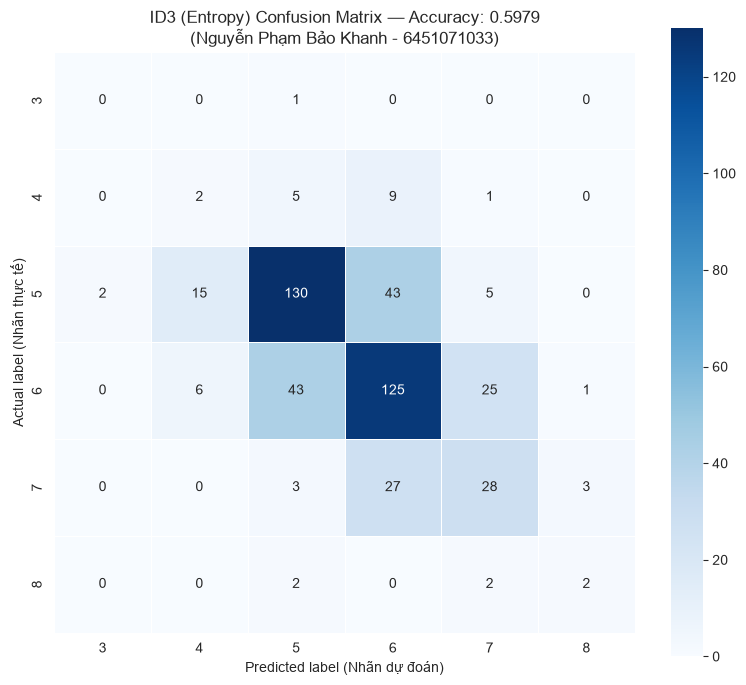

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

id3_clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3_clf.fit(X_train, y_train)
id3_pred = id3_clf.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print(f"ID3 (Entropy) Accuracy: {id3_score:.6f} ({id3_score * 100:.2f}%)")
print(f"Độ sâu toàn cây ID3: {id3_clf.get_depth()} | Số nút lá: {id3_clf.get_n_leaves()}")
print("\nBáo cáo phân lớp (Classification Report - ID3):")
print(metrics.classification_report(y_test, id3_pred, zero_division=0))

class_labels = sorted(labels.unique())
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=class_labels)

plt.figure(figsize=(8, 7))
sns.heatmap(
    id3_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"ID3 (Entropy) Confusion Matrix — Accuracy: {id3_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033


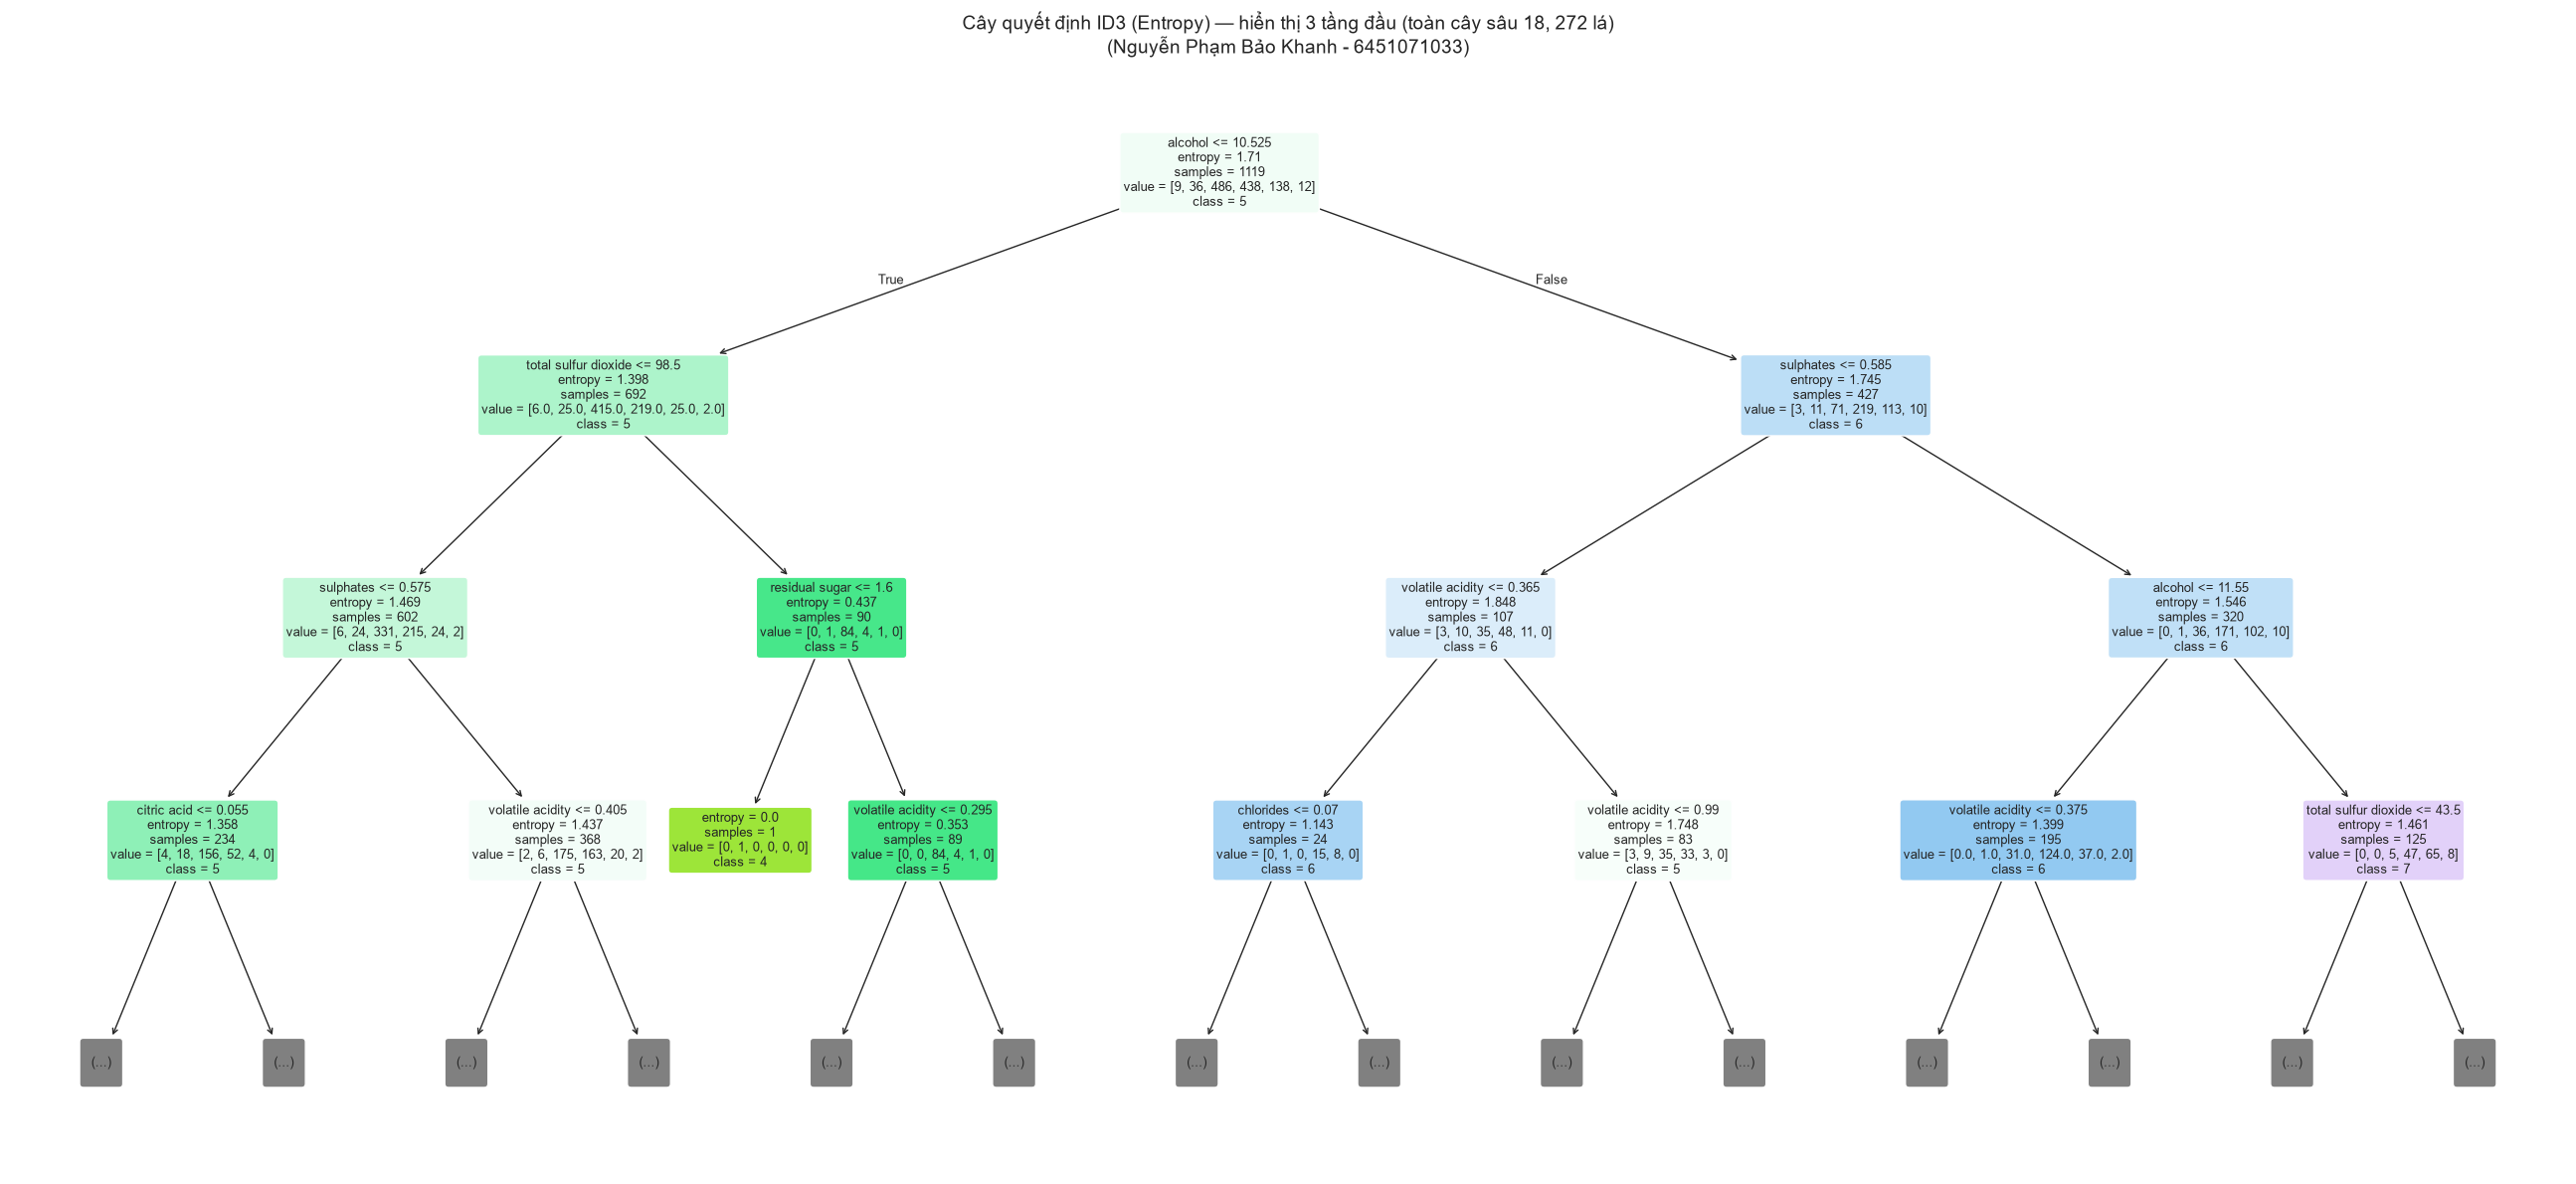

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

# Cây đầy đủ có độ sâu 18 và 272 nút lá nên hiển thị 3 tầng đầu (max_depth=3) để dễ quan sát
fig, ax = plt.subplots(figsize=(26, 12))
tree.plot_tree(
    id3_clf,
    max_depth=3,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in id3_clf.classes_],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.title(
    f"Cây quyết định ID3 (Entropy) — hiển thị 3 tầng đầu (toàn cây sâu {id3_clf.get_depth()}, {id3_clf.get_n_leaves()} lá)\n({STUDENT_NAME} - {MSSV})",
    fontsize=14,
)
plt.tight_layout()
plt.show()

**Nhận xét Câu 7:**
- Mô hình cây quyết định **ID3 (`criterion='entropy'`)** đạt độ chính xác **`59.79%`** (`0.5979`) trên tập kiểm thử `480` mẫu.
- Hai lớp chiếm đa số là `5` (`F1 = 0.69`) và `6` (`F1 = 0.62`) có kết quả khá tốt, lớp `7` đạt `F1 = 0.46`, trong khi lớp thiểu số `3` (`1` mẫu kiểm thử) bị dự đoán sai hoàn toàn (`F1 = 0.00`).
- Cây phát triển đầy đủ đạt độ sâu **`18`** với **`272`** nút lá; ở nút gốc, thuộc tính `alcohol` là tiêu chí phân chia đầu tiên (độ lợi thông tin cao nhất), phù hợp với kết quả phân tích tương quan ở Câu 3.

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
CART (Gini) Accuracy: 0.572917 (57.29%)
Độ sâu toàn cây CART: 19 | Số nút lá: 288

Báo cáo phân lớp (Classification Report - CART):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480



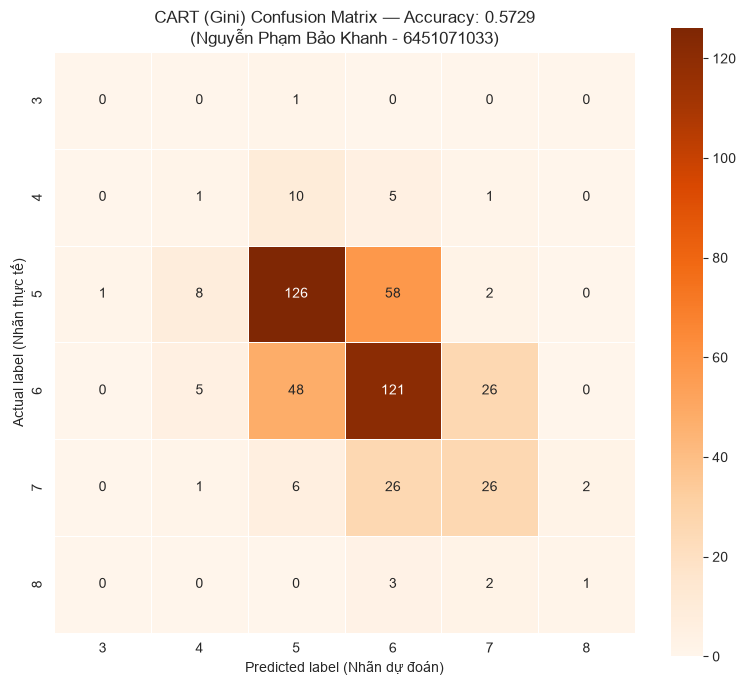

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

cart_clf = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart_clf.fit(X_train, y_train)
cart_pred = cart_clf.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"CART (Gini) Accuracy: {cart_score:.6f} ({cart_score * 100:.2f}%)")
print(f"Độ sâu toàn cây CART: {cart_clf.get_depth()} | Số nút lá: {cart_clf.get_n_leaves()}")
print("\nBáo cáo phân lớp (Classification Report - CART):")
print(metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=class_labels)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cart_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Oranges",
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"CART (Gini) Confusion Matrix — Accuracy: {cart_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033


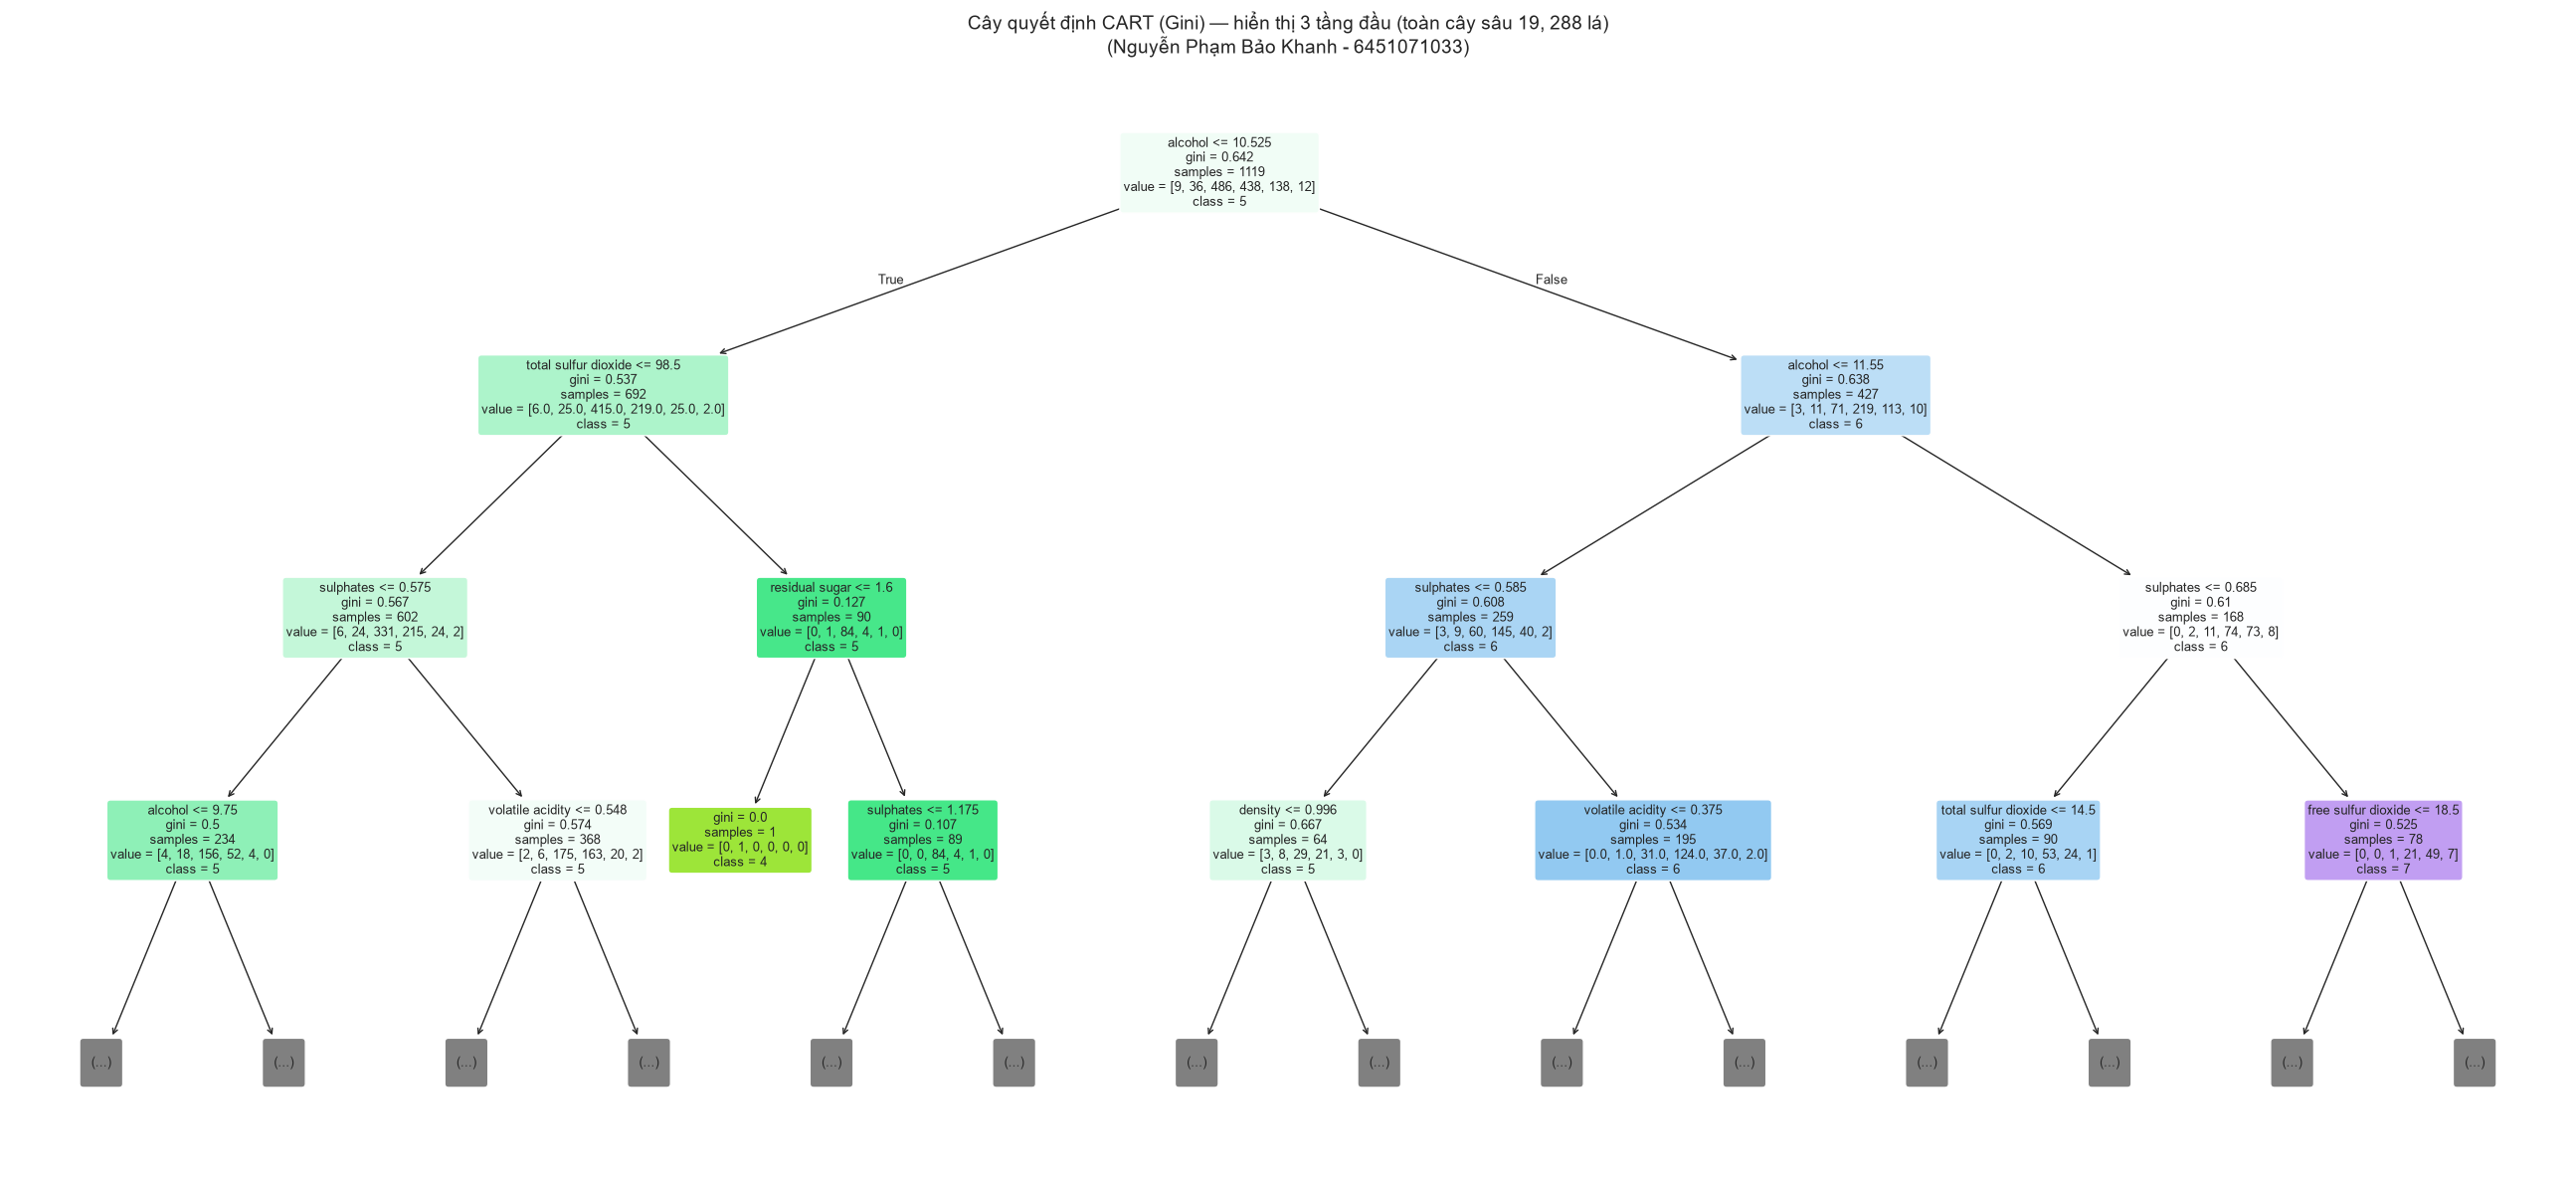

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

# Cây đầy đủ có độ sâu 19 và 288 nút lá nên hiển thị 3 tầng đầu (max_depth=3) để dễ quan sát
fig, ax = plt.subplots(figsize=(26, 12))
tree.plot_tree(
    cart_clf,
    max_depth=3,
    feature_names=list(features_onehot.columns),
    class_names=[str(c) for c in cart_clf.classes_],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.title(
    f"Cây quyết định CART (Gini) — hiển thị 3 tầng đầu (toàn cây sâu {cart_clf.get_depth()}, {cart_clf.get_n_leaves()} lá)\n({STUDENT_NAME} - {MSSV})",
    fontsize=14,
)
plt.tight_layout()
plt.show()

**Nhận xét Câu 8:**
- Mô hình **CART (`criterion='gini'`)** đạt độ chính xác **`57.29%`** (`0.5729`), thấp hơn `2.50%` so với ID3 (`59.79%`).
- Cây CART có độ sâu **`19`** và **`288`** nút lá (phức tạp hơn ID3), dẫn đến `Macro F1 = 0.33` và `Weighted F1 = 0.57`. Tương tự ID3, các sai số chủ yếu rơi vào các lớp chất lượng kề nhau (giữa `5`, `6`, `7`) và các lớp rất hiếm (`3`, `4`, `8`).

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
GaussianNB Accuracy: 0.541667 (54.17%)

Báo cáo phân lớp (Classification Report - GaussianNB):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



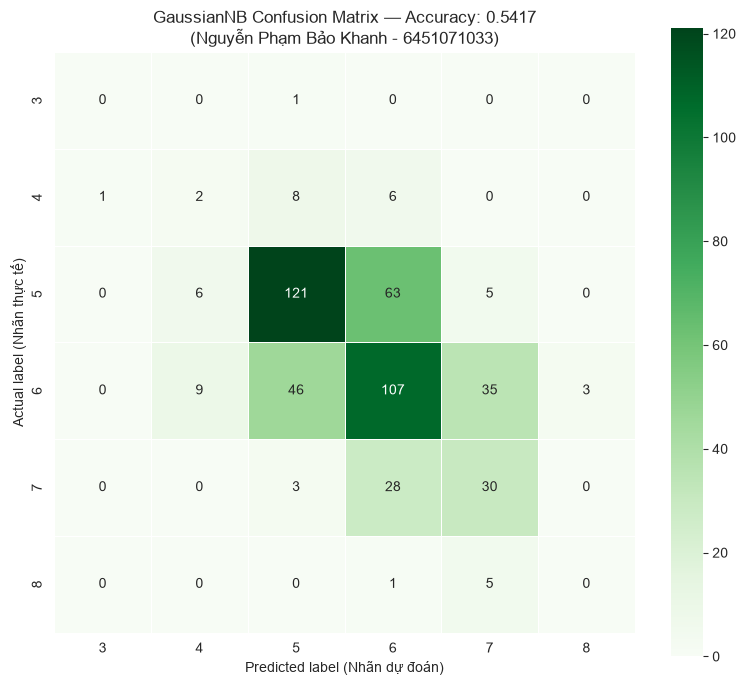

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

gnb = GaussianNB()
gnb.fit(X_train, y_train)
bayes_pred = gnb.predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"GaussianNB Accuracy: {bayes_score:.6f} ({bayes_score * 100:.2f}%)")
print("\nBáo cáo phân lớp (Classification Report - GaussianNB):")
print(metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=class_labels)

plt.figure(figsize=(8, 7))
sns.heatmap(
    bayes_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"GaussianNB Confusion Matrix — Accuracy: {bayes_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

**Nhận xét Câu 9:**
- Mô hình **Naïve Bayes (`GaussianNB`)** đạt độ chính xác **`54.17%`** (`0.5417`), `Weighted F1 = 0.54` và `Macro F1 = 0.29`.
- Cả hai lớp thiểu số cực đoan (`3` và `8`) đều không được dự đoán đúng mẫu nào (`F1 = 0.00`). Lớp `5` (`F1 = 0.65`) và lớp `6` (`F1 = 0.53`) tiếp tục chiếm phần lớn dự đoán đúng.

## Câu 10: So sánh kết quả của các mô hình

Nguyễn Phạm Bảo Khanh - 6451071033
--- Bảng tổng hợp so sánh các mô hình (Red Wine Quality) ---


,Mô hình,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),F1-score (Weighted)
0,ID3 (Entropy),0.5979,0.3664,0.3669,0.3662,0.6026
1,CART (Gini),0.5729,0.3473,0.3171,0.3274,0.5704
2,Naïve Bayes (GaussianNB),0.5417,0.2859,0.2942,0.2890,0.5433



--- F1-score theo từng lớp chất lượng (3..8) ---


,ID3 (Entropy),CART (Gini),Naïve Bayes (GaussianNB)
Quality 3,0.0000,0.0000,0.0000
Quality 4,0.1000,0.0625,0.1176
Quality 5,0.6860,0.6528,0.6471
Quality 6,0.6188,0.5860,0.5284
Quality 7,0.4590,0.4407,0.4412
Quality 8,0.3333,0.2222,0.0000


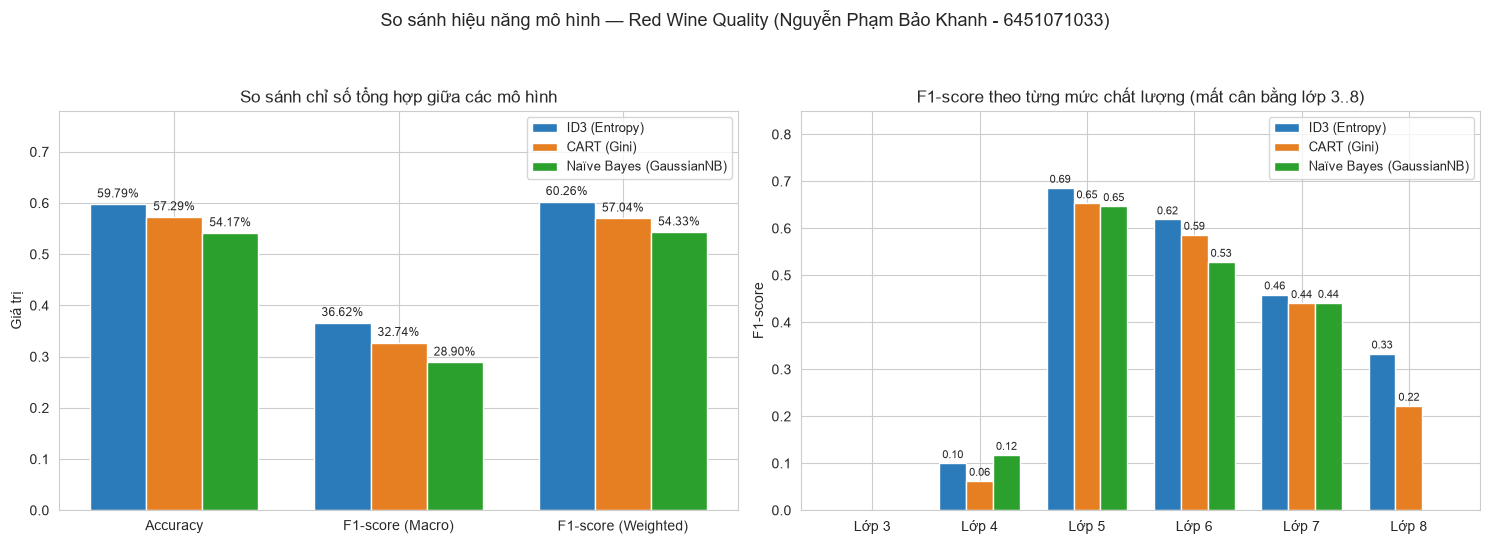

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

models_preds = [
    ("ID3 (Entropy)", id3_pred),
    ("CART (Gini)", cart_pred),
    ("Naïve Bayes (GaussianNB)", bayes_pred),
]

summary_rows = []
per_class_f1 = {}
for name, pred in models_preds:
    summary_rows.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Macro)": metrics.precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (Macro)": metrics.recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (Macro)": metrics.f1_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (Weighted)": metrics.f1_score(y_test, pred, average="weighted", zero_division=0),
    })
    per_class_f1[name] = metrics.f1_score(y_test, pred, labels=class_labels, average=None, zero_division=0)

comparison_df = pd.DataFrame(summary_rows)
print("--- Bảng tổng hợp so sánh các mô hình (Red Wine Quality) ---")
display(comparison_df.round(4))

per_class_df = pd.DataFrame(per_class_f1, index=[f"Quality {c}" for c in class_labels])
print("\n--- F1-score theo từng lớp chất lượng (3..8) ---")
display(per_class_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Biểu đồ 1: Chỉ số tổng hợp
metric_cols = ["Accuracy", "F1-score (Macro)", "F1-score (Weighted)"]
x = np.arange(len(metric_cols))
width = 0.25
colors = ["#2b7bba", "#e67e22", "#2ca02c"]

for idx, (_, row) in enumerate(comparison_df.iterrows()):
    vals = [row[m] for m in metric_cols]
    bars = axes[0].bar(x + (idx - 1) * width, vals, width, label=row["Mô hình"], color=colors[idx])
    for bar in bars:
        h = bar.get_height()
        axes[0].annotate(f"{h:.2%}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_cols)
axes[0].set_ylim(0, 0.78)
axes[0].set_ylabel("Giá trị")
axes[0].set_title("So sánh chỉ số tổng hợp giữa các mô hình")
axes[0].legend(loc="upper right", fontsize=9)

# Biểu đồ 2: F1-score từng lớp 3..8
x_cls = np.arange(len(class_labels))
for idx, (name, _) in enumerate(models_preds):
    vals = per_class_f1[name]
    bars = axes[1].bar(x_cls + (idx - 1) * width, vals, width, label=name, color=colors[idx])
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            axes[1].annotate(f"{h:.2f}", (bar.get_x() + bar.get_width() / 2, h),
                             ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

axes[1].set_xticks(x_cls)
axes[1].set_xticklabels([f"Lớp {c}" for c in class_labels])
axes[1].set_ylim(0, 0.85)
axes[1].set_ylabel("F1-score")
axes[1].set_title("F1-score theo từng mức chất lượng (mất cân bằng lớp 3..8)")
axes[1].legend(loc="upper right", fontsize=9)

fig.suptitle(f"So sánh hiệu năng mô hình — Red Wine Quality ({STUDENT_NAME} - {MSSV})", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Nhận xét & Kết luận Câu 10 (Bài 4 - Red Wine Quality):**
1. **Xếp hạng hiệu năng:** Trên tập dữ liệu `winequality-red.csv` (`1.119` huấn luyện / `480` kiểm thử), **ID3 (Entropy)** đạt kết quả cao nhất (`Accuracy = 59.79%`, `Macro F1 = 0.37`, `Weighted F1 = 0.60`), tiếp theo là **CART (Gini)** (`57.29%`, `Macro F1 = 0.33`, `Weighted F1 = 0.57`) và thấp nhất là **Gaussian Naïve Bayes** (`54.17%`, `Macro F1 = 0.29`, `Weighted F1 = 0.54`).
2. **Tác động của mất cân bằng đa lớp (`quality` từ `3` đến `8`):**
   - Hai lớp trung tâm `5` (`681` mẫu) và `6` (`638` mẫu) chiếm tới `82.5%` toàn bộ dữ liệu, còn các lớp biên `3` (`10` mẫu, test `1`), `4` (`53` mẫu, test `17`) và `8` (`18` mẫu, test `6`) rất ít.
   - Hệ quả là `Macro F1` chỉ đạt `0.29 – 0.37` (thấp hơn nhiều so với `Accuracy` và `Weighted F1`) vì cả 3 mô hình đều đạt `F1 = 0.00` ở lớp `3`, còn `GaussianNB` cũng đạt `0.00` ở lớp `8`.
3. **Vì sao Cây quyết định tốt hơn GaussianNB:** Các đặc trưng hóa lý có tương quan chéo đáng kể (`|r|` lên tới `0.683`) và phân bố lệch chuẩn, vi phạm giả định độc lập & phân phối chuẩn của `GaussianNB`. Cây quyết định (`ID3`, `CART`) chia ngưỡng phi tuyến theo từng vùng đặc trưng nên tách biệt tốt hơn giữa các mức chất lượng liền kề (`5`, `6`, `7`), trong đó tiêu chuẩn `Entropy` phân nhánh cân đối hơn nhẹ so với `Gini`.